In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/priyankasingh27/camera-grandstaff/test-00000-of-00001 (1).parquet
/kaggle/input/datasets/priyankasingh27/camera-grandstaff/train-00000-of-00001 (1).parquet
/kaggle/input/datasets/priyankasingh27/camera-grandstaff/val-00000-of-00001 (1).parquet
/kaggle/input/datasets/priyankasingh27/cnn-t-camera-gs-models/cnn_camaug_best.pt
/kaggle/input/datasets/priyankasingh27/cnn-t-camera-gs-models/cnn_camaug_history.json
/kaggle/input/datasets/priyankasingh27/cnn-t-camera-gs-models/cnn_camaug_last.pt
/kaggle/input/datasets/priyankasingh27/cnn-t-camera-gs-models/vocab.json
/kaggle/input/datasets/priyankasingh27/grandstaff/test-00000-of-00001.parquet
/kaggle/input/datasets/priyankasingh27/grandstaff/train-00000-of-00001.parquet
/kaggle/input/datasets/priyankasingh27/grandstaff/val-00000-of-00001.parquet


In [2]:
import io, json, math, os, random, collections, time
import numpy as np, pandas as pd, torch
from PIL import Image

CFG = dict(
    arch="transformer",          # "transformer" | "rnn"
    epochs=20, batch_size=16, lr=3e-4, warmup_steps=500,
    dropout=0.1, d_model=256, layers=4, heads=8,
    max_train_w=1600, max_train_tok=1000,
    val_subset=1000, seed=0,
    out_dir="/kaggle/working",
)
H = 256
dev = "cuda"

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["seed"])

root = "/kaggle/input/datasets/priyankasingh27/grandstaff"
dfs = {s: pd.read_parquet(f"{root}/{s}-00000-of-00001.parquet") for s in ["train", "val", "test"]}
print({s: len(d) for s, d in dfs.items()})        # 41598 / 4623 / 7661

# ---- lossless tokenizer ----
SEP = {"<s>": " ", "<t>": "\t", "<b>": "\n"}

def tokenize(s):
    s = s.replace(" ", " <s> ").replace("\t", " <t> ").replace("\n", " <b> ").replace("·", " ")
    return s.split()

def detokenize(toks):
    out, prev_sep = [], True
    for t in toks:
        if t in SEP:
            out.append(SEP[t]); prev_sep = True
        else:
            if not prev_sep: out.append("·")
            out.append(t); prev_sep = False
    return "".join(out)

for split, d in dfs.items():
    print(split, "round-trip failures:", sum(detokenize(tokenize(s)) != s for s in d["transcription"]))

{'train': 41598, 'val': 4623, 'test': 7661}
train round-trip failures: 0
val round-trip failures: 0
test round-trip failures: 0


In [3]:
from torch.utils.data import Dataset, DataLoader, Subset, Sampler
from torch.nn.utils.rnn import pad_sequence

# ---- vocab from train only, saved for inference ----
counter = collections.Counter(t for s in dfs["train"]["transcription"] for t in tokenize(s))
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
itos = SPECIALS + sorted(counter)
stoi = {t: i for i, t in enumerate(itos)}
PAD, BOS, EOS, UNK = 0, 1, 2, 3
json.dump(itos, open(f"{CFG['out_dir']}/vocab.json", "w"))

def encode(s):
    return [BOS] + [stoi.get(t, UNK) for t in tokenize(s)] + [EOS]

def decode(ids):
    toks = []
    for i in ids:
        if i == EOS: break
        if i not in (PAD, BOS): toks.append(itos[i])
    return detokenize(toks)

class GrandStaff(Dataset):
    def __init__(self, df, augment=None):          # augment hook stays None until Step 7
        self.img_bytes = [d["bytes"] for d in df["image"]]
        self.texts = df["transcription"].tolist()
        self.widths = [Image.open(io.BytesIO(b)).size[0] for b in self.img_bytes]
        self.ntok = [len(tokenize(s)) for s in self.texts]
        self.augment = augment
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        img = Image.open(io.BytesIO(self.img_bytes[i])).convert("L")
        if self.augment is not None:
            img = self.augment(img)
        a = 1.0 - np.asarray(img, dtype=np.float32) / 255.0      # ink = 1
        if a.shape[0] < H:
            a = np.pad(a, ((0, H - a.shape[0]), (0, 0)))
        return torch.from_numpy(a).unsqueeze(0), torch.tensor(encode(self.texts[i]))

def collate(batch):
    imgs, seqs = zip(*batch)
    widths = torch.tensor([im.shape[-1] for im in imgs])
    x = torch.zeros(len(imgs), 1, H, int(widths.max()))
    for k, im in enumerate(imgs):
        x[k, :, :, : im.shape[-1]] = im
    seqs = pad_sequence(seqs, batch_first=True, padding_value=PAD)
    return {"image": x, "widths": widths, "tgt_in": seqs[:, :-1], "tgt_out": seqs[:, 1:]}

class WidthBucketSampler(Sampler):
    def __init__(self, widths, batch_size, shuffle=True, chunk=50):
        self.w, self.bs, self.shuffle, self.chunk = np.array(widths), batch_size, shuffle, chunk
    def __iter__(self):
        idx = np.random.permutation(len(self.w)) if self.shuffle else np.arange(len(self.w))
        step, batches = self.bs * self.chunk, []
        for s in range(0, len(idx), step):
            c = idx[s:s + step]
            c = c[np.argsort(self.w[c])]
            batches += [c[j:j + self.bs].tolist() for j in range(0, len(c), self.bs)]
        if self.shuffle: random.shuffle(batches)
        return iter(batches)
    def __len__(self):
        return -(-len(self.w) // self.bs)

train_ds, val_ds, test_ds = (GrandStaff(dfs[s]) for s in ("train", "val", "test"))

# training-only filter; val and test are never filtered
keep = [i for i in range(len(train_ds))
        if train_ds.widths[i] <= CFG["max_train_w"] and train_ds.ntok[i] <= CFG["max_train_tok"]]
train_dl = DataLoader(Subset(train_ds, keep), collate_fn=collate, num_workers=2,
                      batch_sampler=WidthBucketSampler([train_ds.widths[i] for i in keep],
                                                       CFG["batch_size"]))

# fixed val subset for model selection
val_idx = sorted(np.random.RandomState(123).choice(len(val_ds), CFG["val_subset"],
                                                   replace=False).tolist())

# checks
print("train kept:", len(keep), "/", len(train_ds))              # expect 40684 / 41598
print("vocab incl. specials:", len(itos))                        # expect 188
print("id round-trip failures:", sum(decode(encode(s)) != s for s in train_ds.texts))

train kept: 40684 / 41598
vocab incl. specials: 188
id round-trip failures: 0


In [4]:
import torchvision
import torch.nn as nn, torch.nn.functional as F

def pos2d(d, h, w, device):
    q = d // 4
    freq = torch.exp(torch.arange(q, device=device) * (-math.log(10000.0) / q))
    ys = torch.arange(h, device=device)[:, None] * freq[None]
    xs = torch.arange(w, device=device)[:, None] * freq[None]
    pe_y = torch.cat([ys.sin(), ys.cos()], 1)
    pe_x = torch.cat([xs.sin(), xs.cos()], 1)
    return torch.cat([pe_y[:, None].expand(h, w, d // 2),
                      pe_x[None].expand(h, w, d // 2)], 2)           # (h, w, d)

def pos1d(T, d, device):
    pos = torch.arange(T, device=device)[:, None]
    freq = torch.exp(torch.arange(0, d, 2, device=device) * (-math.log(10000.0) / d))
    pe = torch.zeros(T, d, device=device)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * freq), torch.cos(pos * freq)
    return pe

class OMRModel(nn.Module):
    STRIDE = 16
    def __init__(self, vocab, d=256, layers=4, heads=8, ff=1024, drop=0.1):
        super().__init__()
        r = torchvision.models.resnet34(weights=None)
        r.conv1 = nn.Conv2d(1, 64, 7, 2, 3, bias=False)
        self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool,
                                      r.layer1, r.layer2, r.layer3)
        self.proj = nn.Conv2d(256, d, 1)
        self.embed = nn.Embedding(vocab, d, padding_idx=PAD)
        self.drop = nn.Dropout(drop)
        layer = nn.TransformerDecoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, layers, norm=nn.LayerNorm(d))
        self.out = nn.Linear(d, vocab)

    def encode_img(self, img, widths):
        f = self.proj(self.backbone(img))                            # (B, d, h, w)
        B, d, h, w = f.shape
        f = f + pos2d(d, h, w, f.device).permute(2, 0, 1)[None].to(f.dtype)
        mem = f.flatten(2).transpose(1, 2)                           # (B, h*w, d)
        valid = torch.ceil(widths.to(f.device) / self.STRIDE).long()
        col_pad = torch.arange(w, device=f.device)[None] >= valid[:, None]
        mem_pad = col_pad[:, None, :].expand(B, h, w).reshape(B, h * w)
        return mem, mem_pad

    def decode_tokens(self, tgt_in, mem, mem_pad):
        T = tgt_in.size(1)
        x = self.embed(tgt_in) + pos1d(T, self.embed.embedding_dim, tgt_in.device)[None]
        x = self.drop(x)
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), 1)
        return self.out(self.decoder(x, mem, tgt_mask=causal, memory_key_padding_mask=mem_pad))

    def forward(self, img, widths, tgt_in):
        mem, mem_pad = self.encode_img(img, widths)
        return self.decode_tokens(tgt_in, mem, mem_pad)


In [5]:
CFG.update(eval_every=2, ser_n=300, lr_floor=0.05, grad_clip=1.0, resume=True)

# ---------- metrics ----------
try:
    import editdistance
    edit = editdistance.eval
except Exception:
    def edit(a, b):
        prev = list(range(len(b) + 1))
        for i, x in enumerate(a, 1):
            cur = [i]
            for j, y in enumerate(b, 1):
                cur.append(min(prev[j] + 1, cur[j-1] + 1, prev[j-1] + (x != y)))
            prev = cur
        return prev[-1]

def ids_to_tokens(ids):
    out = []
    for i in ids:
        if i == EOS: break
        if i not in (PAD, BOS): out.append(itos[i])
    return out

@torch.no_grad()
def evaluate_ser(model, ds, idx, bs=16, max_len=1800, drop_n=False):
    """token edit distance / reference length; returns (mean per-sample, corpus-level), in %"""
    idx = sorted(idx, key=lambda i: ds.widths[i])
    per, errs, tot = [], 0, 0
    for s in range(0, len(idx), bs):
        chunk = idx[s:s + bs]
        batch = collate([ds[i] for i in chunk])
        refs = [tokenize(ds.texts[i]) for i in chunk]
        if drop_n: refs = [[t for t in r if t != "n"] for r in refs]
        for p, r in zip(greedy(model, batch, max_len=max_len), refs):
            e = edit(ids_to_tokens(p), r)
            per.append(e / len(r)); errs += e; tot += len(r)
    return 100 * float(np.mean(per)), 100 * errs / tot


In [6]:
import torch.nn.functional as F

def _proj(attn, x, which):               # 0 = q, 1 = k, 2 = v from nn.MultiheadAttention
    d = attn.embed_dim
    return F.linear(x, attn.in_proj_weight[which*d:(which+1)*d],
                    attn.in_proj_bias[which*d:(which+1)*d])
def _heads(x, H):
    B, T, d = x.shape
    return x.view(B, T, H, d // H).transpose(1, 2)
def _merge(x):
    B, H, T, dh = x.shape
    return x.transpose(1, 2).reshape(B, T, H * dh)

class CachedDecoder:
    def __init__(self, model, mem, mem_pad, max_len=1800):
        self.m, self.L = model, model.decoder.layers
        self.H = self.L[0].self_attn.num_heads
        self.pe = pos1d(max_len, model.embed.embedding_dim, mem.device)
        self.mask = (~mem_pad)[:, None, None, :]                  # True = attend
        self.ck = [_heads(_proj(l.multihead_attn, mem, 1), self.H) for l in self.L]
        self.cv = [_heads(_proj(l.multihead_attn, mem, 2), self.H) for l in self.L]
        self.sk = [None] * len(self.L); self.sv = [None] * len(self.L)

    def step(self, tok, t):                                        # tok: (B,), returns (B, vocab)
        m = self.m
        x = (m.embed(tok) + self.pe[t])[:, None]                   # (B, 1, d)
        for i, l in enumerate(self.L):
            h = l.norm1(x)
            q, k, v = (_heads(_proj(l.self_attn, h, j), self.H) for j in range(3))
            self.sk[i] = k if self.sk[i] is None else torch.cat([self.sk[i], k], 2)
            self.sv[i] = v if self.sv[i] is None else torch.cat([self.sv[i], v], 2)
            x = x + l.self_attn.out_proj(_merge(F.scaled_dot_product_attention(q, self.sk[i], self.sv[i])))
            q = _heads(_proj(l.multihead_attn, l.norm2(x), 0), self.H)
            a = F.scaled_dot_product_attention(q, self.ck[i], self.cv[i], attn_mask=self.mask)
            x = x + l.multihead_attn.out_proj(_merge(a))
            x = x + l.linear2(l.activation(l.linear1(l.norm3(x))))
        return m.out(m.decoder.norm(x))[:, 0]

@torch.no_grad()
def greedy_fast(model, batch, max_len=1800):
    model.eval()
    with torch.autocast("cuda", dtype=torch.float16):
        mem, mem_pad = model.encode_img(batch["image"].to(dev), batch["widths"])
        dc = CachedDecoder(model, mem, mem_pad, max_len)
        B = mem.size(0)
        tok = torch.full((B,), BOS, device=dev)
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        out = []
        for t in range(max_len):
            nxt = dc.step(tok, t).argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
            out.append(nxt); done |= nxt == EOS; tok = nxt
            if done.all(): break
    return torch.stack(out, 1).tolist()

greedy = greedy_fast          # evaluate_ser now uses the fast decoder


In [7]:
import glob, collections
PATH = glob.glob("/kaggle/input/**/cnn_camaug_best.pt", recursive=True)[0]
ck = torch.load(PATH, map_location=dev, weights_only=False)
model = OMRModel(len(itos), d=256, layers=4, heads=8, drop=0.0).to(dev)
model.load_state_dict(ck["model"]); model.eval()
print("loaded epoch", ck["epoch"], "| selection score", round(ck["sel"], 2))

saved = json.load(open(os.path.join(os.path.dirname(PATH), "vocab.json")))
print("vocabulary identical to training:", saved == itos, "|", len(itos), "tokens")

@torch.no_grad()
def predict(model, ds, idx, bs=32, max_len=1800):
    hyps, t0 = {}, time.time()
    order = sorted(idx, key=lambda i: ds.widths[i])
    for s in range(0, len(order), bs):
        chunk = order[s:s + bs]
        for i, p in zip(chunk, greedy_fast(model, collate([ds[i] for i in chunk]), max_len)):
            hyps[i] = ids_to_tokens(p)
    print(f"decoded {len(idx)} samples in {time.time()-t0:.0f}s")
    return hyps

def score(ds, hyps, drop_n=False):
    rows = []
    for i, h in hyps.items():
        r = tokenize(ds.texts[i])
        if drop_n: r = [t for t in r if t != "n"]
        rows.append((i, len(r), edit(h, r)))
    return rows

def summarize(rows, name=""):
    n = np.array([r[1] for r in rows]); e = np.array([r[2] for r in rows])
    print(f"{name}: mean SER {100*np.mean(e/n):.2f} | corpus SER {100*e.sum()/n.sum():.2f} "
          f"| exact match {100*np.mean(e==0):.1f}% | n={len(rows)}")

def by_length(rows, edges=(0, 200, 400, 700, 1000, 10**9)):
    n = np.array([r[1] for r in rows]); e = np.array([r[2] for r in rows])
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (n >= lo) & (n < hi)
        if m.sum():
            print(f"  ref len {lo:>4}-{'inf' if hi == 10**9 else hi:<5} n={m.sum():4d} "
                  f"mean SER {100*np.mean(e[m]/n[m]):6.2f} | corpus {100*e[m].sum()/n[m].sum():6.2f} "
                  f"| exact {100*np.mean(e[m]==0):5.1f}%")

# sanity: reproduce the training-time number on the same 300-sample slice
ser_idx = val_idx[::max(1, len(val_idx) // 300)][:300]
h300 = predict(model, val_ds, ser_idx)
summarize(score(val_ds, h300), "300-slice")       # expect close to the training-time SER

# full val
val_all = list(range(len(val_ds)))
hv = predict(model, val_ds, val_all)
rows_v = score(val_ds, hv)
summarize(rows_v, "FULL VAL"); by_length(rows_v)

loaded epoch 19 | selection score 1.09
vocabulary identical to training: True | 188 tokens
decoded 300 samples in 29s
300-slice: mean SER 0.93 | corpus SER 1.49 | exact match 70.7% | n=300
decoded 4623 samples in 401s
FULL VAL: mean SER 1.27 | corpus SER 2.01 | exact match 68.0% | n=4623
  ref len    0-200   n= 437 mean SER   1.15 | corpus   1.02 | exact  85.8%
  ref len  200-400   n=2705 mean SER   0.74 | corpus   0.75 | exact  76.6%
  ref len  400-700   n=1288 mean SER   1.23 | corpus   1.30 | exact  52.6%
  ref len  700-1000  n= 162 mean SER   5.35 | corpus   5.50 | exact  11.7%
  ref len 1000-inf   n=  31 mean SER  29.52 | corpus  31.34 | exact   0.0%


In [9]:
def spine_ok(toks):
    lines = [l for l in detokenize(toks).split("\n") if l != ""]
    ncols = None
    for l in lines:
        cols = l.split("\t")
        if ncols is None: ncols = len(cols)
        if len(cols) != ncols: return False
        if all(c.startswith("*") for c in cols):         # interpretation line: update spine count
            new, k = 0, 0
            while k < len(cols):
                if cols[k] == "*^": new += 2; k += 1
                elif cols[k] == "*v":
                    j = k
                    while j < len(cols) and cols[j] == "*v": j += 1
                    new += max(1, (j - k) // 2); k = j   # assumes merges come in pairs
                else: new += 1; k += 1
            ncols = new
    return True

ref_ok = [spine_ok(tokenize(t)) for t in val_ds.texts]
print("references passing:", round(100 * np.mean(ref_ok), 2), "%")
bad = [i for i, ok in zip(val_all, ref_ok) if not ok]
if bad: print("first failing reference:", bad[0])

hyp_ok = {i: spine_ok(hv[i]) for i in val_all}
print("predictions passing:", round(100 * np.mean(list(hyp_ok.values())), 2), "%")
exact = {r[0]: r[2] == 0 for r in rows_v}
print("among predictions that fail:", sum(not v for v in hyp_ok.values()),
      "| of those, exact matches:", sum(exact[i] and not hyp_ok[i] for i in val_all))   # should be 0

references passing: 100.0 %
predictions passing: 99.05 %
among predictions that fail: 44 | of those, exact matches: 0


In [8]:
CAM = "/kaggle/input/datasets/priyankasingh27/camera-grandstaff/val-00000-of-00001 (1).parquet"
def fit_height(img):
    if img.height == H: return img
    return img.resize((max(8, round(img.width * H / img.height)), H), Image.BILINEAR)
cam_ds = GrandStaff(pd.read_parquet(CAM)); cam_ds.augment = fit_height
n = len(cam_ds); idx = list(range(n))
print("labels identical to clean val:", float(np.mean([a == b for a, b in zip(cam_ds.texts, val_ds.texts)])))

hc = predict(model, cam_ds, idx)
rc, rv = score(cam_ds, hc), score(val_ds, hv)
summarize(rv, "CLEAN val (same systems)"); summarize(rc, "CAMERA val"); by_length(rc)
print("structure valid: camera %.1f%% | clean %.1f%%" % (100 * np.mean([spine_ok(hc[i]) for i in idx]), 100 * np.mean([spine_ok(hv[i]) for i in idx])))
hs = np.array([Image.open(io.BytesIO(b)).size[1] for b in cam_ds.img_bytes])
w = np.array([round(a * H / b) for a, b in zip(cam_ds.widths, hs)])
err = {r[0]: r[2] / r[1] for r in rc}; errv = {r[0]: r[2] / r[1] for r in rv}
for name, m in (("width <= 1600", w <= 1600), ("width > 1600", w > 1600)):
    ii = [i for i in idx if m[i]]
    print(f"{name}: n={len(ii)} | camera mean SER {100*np.mean([err[i] for i in ii]):.2f} | clean {100*np.mean([errv[i] for i in ii]):.2f}")

labels identical to clean val: 1.0
decoded 4623 samples in 475s
CLEAN val (same systems): mean SER 1.27 | corpus SER 2.01 | exact match 68.0% | n=4623
CAMERA val: mean SER 1.66 | corpus SER 2.83 | exact match 67.4% | n=4623
  ref len    0-200   n= 437 mean SER   1.00 | corpus   0.90 | exact  87.4%
  ref len  200-400   n=2705 mean SER   0.70 | corpus   0.72 | exact  77.6%
  ref len  400-700   n=1288 mean SER   2.15 | corpus   2.36 | exact  48.6%
  ref len  700-1000  n= 162 mean SER   8.87 | corpus   9.05 | exact   4.3%
  ref len 1000-inf   n=  31 mean SER  37.03 | corpus  38.86 | exact   0.0%


NameError: name 'spine_ok' is not defined

In [11]:
print("structure valid: camera %.1f%% | clean %.1f%%" % (100 * np.mean([spine_ok(hc[i]) for i in idx]), 100 * np.mean([spine_ok(hv[i]) for i in idx])))
hs = np.array([Image.open(io.BytesIO(b)).size[1] for b in cam_ds.img_bytes])
w = np.array([round(a * H / b) for a, b in zip(cam_ds.widths, hs)])
err = {r[0]: r[2] / r[1] for r in rc}; errv = {r[0]: r[2] / r[1] for r in rv}
for name, m in (("width <= 1600", w <= 1600), ("width > 1600", w > 1600)):
    ii = [i for i in idx if m[i]]
    print(f"{name}: n={len(ii)} | camera mean SER {100*np.mean([err[i] for i in ii]):.2f} | clean {100*np.mean([errv[i] for i in ii]):.2f}")

structure valid: camera 99.3% | clean 99.0%
width <= 1600: n=4239 | camera mean SER 0.87 | clean 0.93
width > 1600: n=384 | camera mean SER 10.42 | clean 5.03


In [12]:
def classify(t):
    if t in ("<s>", "<t>", "<b>"): return "layout"
    if t[0] in "*=": return "header/barline"
    if t.isdigit(): return "duration"
    if t in ("#", "-", "n", "##", "--"): return "accidental"
    if all(c in "abcdefgABCDEFG" for c in t): return "pitch"
    if t == "r": return "rest"
    return "other"

def align_errors(hyp, ref):
    n, m = len(ref), len(hyp)
    D = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): D[i][0] = i
    for j in range(m + 1): D[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i][j] = min(D[i-1][j] + 1, D[i][j-1] + 1, D[i-1][j-1] + (ref[i-1] != hyp[j-1]))
    i, j, wrong, ins = n, m, collections.Counter(), 0
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i][j] == D[i-1][j-1] + (ref[i-1] != hyp[j-1]):
            if ref[i-1] != hyp[j-1]: wrong[classify(ref[i-1])] += 1
            i -= 1; j -= 1
        elif i > 0 and D[i][j] == D[i-1][j] + 1:
            wrong[classify(ref[i-1])] += 1; i -= 1
        else:
            ins += 1; j -= 1
    return wrong, ins

sub = sorted(hv)[::max(1, len(hv) // 300)][:300]          # 300-sample subset, pure-python DP is slow
tot, wr, ins = collections.Counter(), collections.Counter(), 0
for i in sub:
    r = tokenize(val_ds.texts[i]); tot.update(classify(t) for t in r)
    w, k = align_errors(hv[i], r); wr.update(w); ins += k
print("error rate by reference-token class (substitutions + deletions):")
for c in tot: print(f"  {c:15s} {100*wr[c]/tot[c]:6.2f}%   ({wr[c]} / {tot[c]})")
print("insertions:", ins, "| total ref tokens:", sum(tot.values()))

def structure_ok(toks):
    lines = [l for l in detokenize(toks).split("\n") if l != ""]
    return len({len(l.split("\t")) for l in lines}) == 1

ref_ok = np.mean([structure_ok(tokenize(t)) for t in val_ds.texts])
hyp_ok = np.mean([structure_ok(hv[i]) for i in val_all])
hit_cap = np.mean([len(hv[i]) >= 1800 for i in val_all])
print(f"column-consistent: references {100*ref_ok:.1f}% | predictions {100*hyp_ok:.1f}% | hit decode cap {100*hit_cap:.2f}%")

error rate by reference-token class (substitutions + deletions):
  header/barline    2.89%   (242 / 8379)
  layout            1.05%   (391 / 37214)
  duration          1.28%   (267 / 20920)
  pitch             1.94%   (377 / 19422)
  accidental        1.47%   (148 / 10097)
  other             2.71%   (447 / 16519)
  rest              1.61%   (25 / 1552)
insertions: 637 | total ref tokens: 114103
column-consistent: references 56.0% | predictions 55.9% | hit decode cap 0.17%


In [21]:
hyp_ok = {i: spine_ok(hv[i]) for i in val_all}
print("predictions passing: %.2f%%" % (100 * np.mean(list(hyp_ok.values()))))
fail = [i for i in val_all if not hyp_ok[i]]
L = [len(tokenize(val_ds.texts[i])) for i in fail]
print(len(fail), "failures | ref length 10/50/90th percentile:", np.percentile(L, [10, 50, 90]), "| of which 700+ tokens:", sum(l >= 700 for l in L))

predictions passing: 99.05%
44 failures | ref length 10/50/90th percentile: [ 500.8  871.  1338.5] | of which 700+ tokens: 26


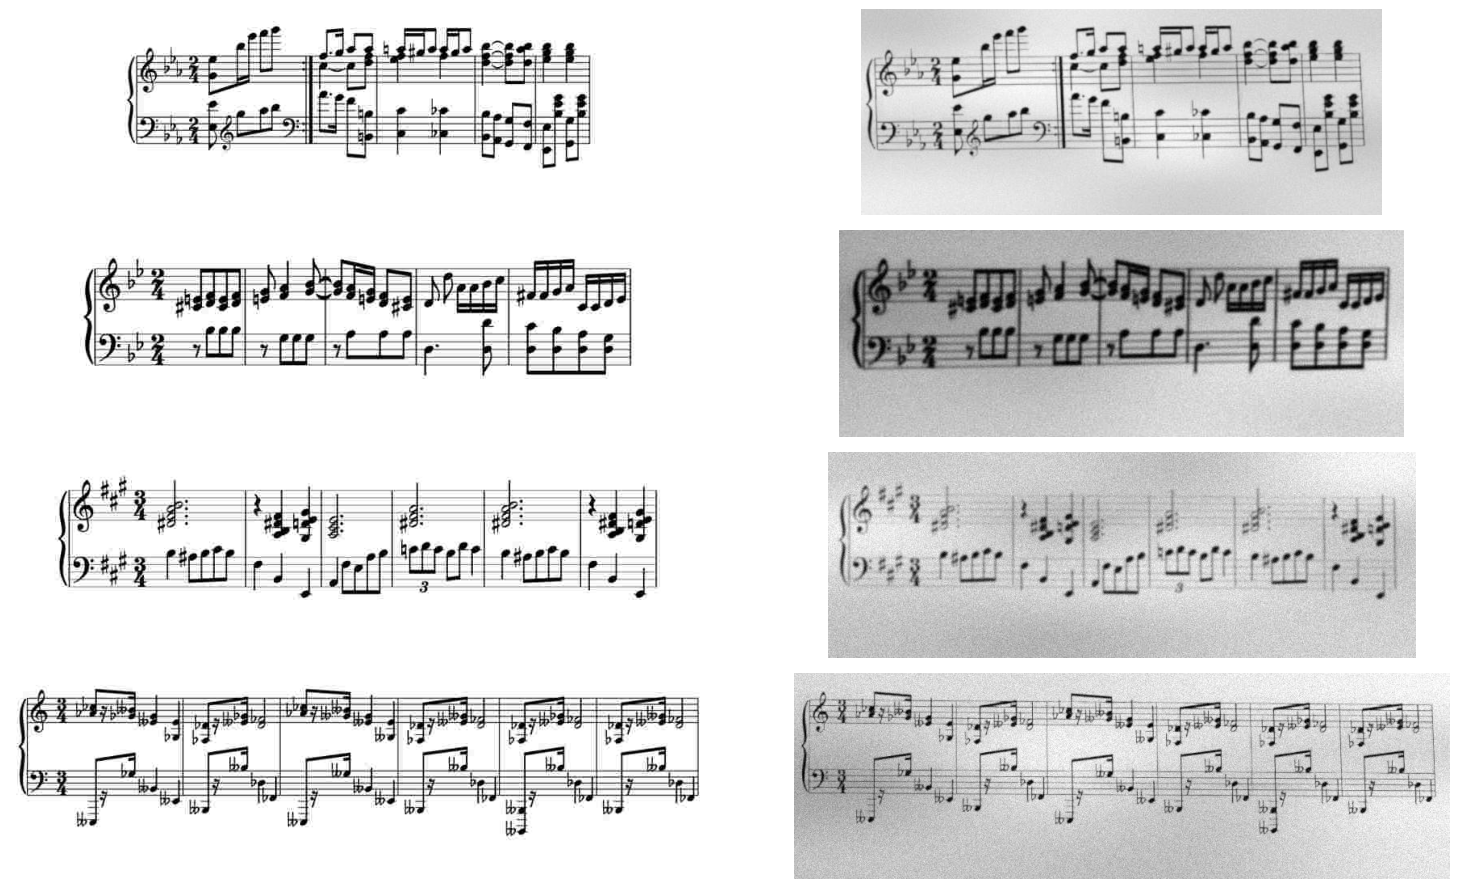

In [15]:
#the augmentation function and a visual check
import cv2, copy, random
import matplotlib.pyplot as plt
cv2.setNumThreads(0)

class Augment:
    ALL = ("scale", "geom", "blur", "ink", "illum", "noise", "jpeg")
    def __init__(self, strength=1.0, groups=ALL, deterministic=False, p=0.7):
        self.s, self.groups, self.det, self.p = strength, set(groups), deterministic, p

    def __call__(self, img):
        a = np.asarray(img.convert("L"), dtype=np.uint8)
        h, w = a.shape
        if self.det:    # same degradation for the same image every time (for evaluation)
            rng = np.random.default_rng(int(a[::13, ::29].astype(np.int64).sum()) % (2**32))
        else:
            rng = np.random.default_rng(random.getrandbits(32))
        on = lambda g: g in self.groups and rng.random() < self.p
        s = self.s

        # --- geometry: scale + small rotation/shear + corner jitter, one homography ---
        sc = rng.uniform(1 - 0.12 * s, 1 + 0.08 * s) if on("scale") else 1.0
        geom = on("geom")
        amax = min(np.arctan(6 / (w / 2)), np.deg2rad(1.5))      # keep far ends within ~6 px vertically
        ang = rng.uniform(-amax, amax) * s if geom else 0.0
        shear = rng.uniform(-0.03, 0.03) * s if geom else 0.0
        jit = rng.uniform(-1, 1, (4, 2)) * np.array([min(0.01 * w, 20), 8.0]) * s if geom else np.zeros((4, 2))
        src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        Hc = cv2.getPerspectiveTransform(src, (src + jit).astype(np.float32))
        wo = max(64, int(round(w * sc)))
        R = np.array([[np.cos(ang), -np.sin(ang), 0], [np.sin(ang), np.cos(ang), 0], [0, 0, 1]])
        Sh = np.array([[1, shear, 0], [0, 1, 0], [0, 0, 1]])
        S = np.diag([sc, sc, 1.0])
        Tin = np.array([[1, 0, -w / 2], [0, 1, -h / 2], [0, 0, 1]])
        Tout = np.array([[1, 0, wo / 2], [0, 1, H / 2], [0, 0, 1]])
        a = cv2.warpPerspective(a, Tout @ R @ Sh @ S @ Tin @ Hc, (wo, H),
                                flags=cv2.INTER_LINEAR, borderValue=255)

        # --- ink thickness (erode = min filter = thicker dark ink; dilate = thinner) ---
        if on("ink"):
            k = np.ones((2, 2), np.uint8)
            a = cv2.erode(a, k) if rng.random() < 0.5 else cv2.dilate(a, k)
        # --- blur ---
        if on("blur"):
            a = cv2.GaussianBlur(a, (0, 0), rng.uniform(0.3, 1.3) * s)

        f = a.astype(np.float32)
        # --- paper tone, shading gradient, soft blotches ---
        if on("illum"):
            yy, xx = np.mgrid[0:H, 0:wo].astype(np.float32)
            th = rng.uniform(0, 2 * np.pi)
            g = np.cos(th) * xx / wo + np.sin(th) * yy / H
            g = (g - g.min()) / (np.ptp(g) + 1e-6)
            blot = cv2.resize(rng.normal(0, 1, (4, max(4, wo // 200))).astype(np.float32),
                              (wo, H), interpolation=cv2.INTER_CUBIC)
            f = f * (1 - rng.uniform(0, 0.35) * s * g) * (1 + 0.05 * s * blot) * rng.uniform(0.8, 1.0)
        # --- sensor noise ---
        if on("noise"):
            f = f + rng.normal(0, rng.uniform(2, 12) * s, f.shape)
        a = np.clip(f, 0, 255).astype(np.uint8)
        # --- JPEG artifacts ---
        if on("jpeg"):
            q = int(np.clip(rng.uniform(95 - 60 * s, 95), 20, 95))
            a = cv2.imdecode(cv2.imencode(".jpg", a, [cv2.IMWRITE_JPEG_QUALITY, q])[1], 0)
        return Image.fromarray(a)

# visual check: left = clean, right = heavy augmentation, 4 val samples
fig, ax = plt.subplots(4, 2, figsize=(16, 9))
for r, i in enumerate([0, 50, 400, 1200]):
    im = Image.open(io.BytesIO(val_ds.img_bytes[i])).convert("L")
    ax[r, 0].imshow(im, cmap="gray"); ax[r, 1].imshow(Augment(1.0, p=1.0)(im), cmap="gray")
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()

In [17]:
import copy
val_all = list(range(len(val_ds)))
ser_idx = val_idx[::max(1, len(val_idx) // 300)][:300]

def run(name, aug, idx):
    d = copy.copy(val_ds); d.augment = aug
    h = predict(model, d, idx)
    summarize(score(d, h), name)
    print(f"   structure valid: {100 * np.mean([spine_ok(h[i]) for i in idx]):.1f}%")

def spine_ok(toks):
    lines = [l for l in detokenize(toks).split("\n") if l != ""]
    ncols = None
    for l in lines:
        cols = l.split("\t")
        if ncols is None: ncols = len(cols)
        if len(cols) != ncols: return False
        if all(c.startswith("*") for c in cols):
            new, k = 0, 0
            while k < len(cols):
                if cols[k] == "*^": new += 2; k += 1
                elif cols[k] == "*v":
                    j = k
                    while j < len(cols) and cols[j] == "*v": j += 1
                    new += max(1, (j - k) // 2); k = j
                else: new += 1; k += 1
            ncols = new
    return True

class ShiftPad:
    def __init__(self, px): self.px = px
    def __call__(self, img):
        if self.px == 0: return img
        out = Image.new("L", (img.width + self.px, img.height), 255)
        out.paste(img, (self.px, 0)); return out

class RightPad:
    def __init__(self, px): self.px = px
    def __call__(self, img):
        out = Image.new("L", (img.width + self.px, img.height), 255)
        out.paste(img, (0, 0)); return out

def vshift(dy):
    def f(img):
        out = Image.new("L", img.size, 255); out.paste(img.convert("L"), (0, dy)); return out
    return f

def rescale(sc):
    def f(img):
        im = img.convert("L"); r = im.resize((max(64, int(im.width * sc)), int(im.height * sc)), Image.BILINEAR)
        out = Image.new("L", (r.width, 256), 255); out.paste(r, (0, 0)); return out
    return f

rng = np.random.RandomState(1)
cand = [i for i in val_all if val_ds.widths[i] < 700]
narrow = rng.choice(cand, 150, replace=False).tolist()      # same 150 systems as the baseline tests

In [18]:
def xstretch(f): return lambda img: img.convert("L").resize((int(img.width * f), img.height), Image.BILINEAR)
def blur(sig): return lambda img: Image.fromarray(cv2.GaussianBlur(np.asarray(img.convert("L")), (0, 0), sig))
def wave(amp, period=180):
    def g(img):
        a = np.asarray(img.convert("L")); h, w = a.shape
        yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
        out = cv2.remap(a, xx + 0.5 * amp * np.sin(2 * np.pi * yy / (0.7 * period)),
                        yy + amp * np.sin(2 * np.pi * xx / period), cv2.INTER_LINEAR, borderValue=255)
        return Image.fromarray(out)
    return g
for name, aug in ([(f"x-stretch {f}", xstretch(f)) for f in (1.2, 1.4, 1.6)] + [(f"blur {s}", blur(s)) for s in (1.5, 2.5)] +
                  [(f"wave {a}", wave(a)) for a in (2, 4)] +
                  [("stretch 1.4 + blur 1.5 + wave 3", lambda im: wave(3)(blur(1.5)(xstretch(1.4)(im))))]):
    run(name, aug, ser_idx)

decoded 300 samples in 29s
x-stretch 1.2: mean SER 1.38 | corpus SER 2.17 | exact match 68.3% | n=300
   structure valid: 100.0%
decoded 300 samples in 30s
x-stretch 1.4: mean SER 2.11 | corpus SER 3.55 | exact match 66.0% | n=300
   structure valid: 99.3%
decoded 300 samples in 37s
x-stretch 1.6: mean SER 3.54 | corpus SER 6.10 | exact match 61.0% | n=300
   structure valid: 99.0%
decoded 300 samples in 28s
blur 1.5: mean SER 1.03 | corpus SER 1.60 | exact match 68.0% | n=300
   structure valid: 99.7%
decoded 300 samples in 32s
blur 2.5: mean SER 1.45 | corpus SER 2.53 | exact match 60.3% | n=300
   structure valid: 99.7%
decoded 300 samples in 32s
wave 2: mean SER 1.34 | corpus SER 2.37 | exact match 67.3% | n=300
   structure valid: 98.7%
decoded 300 samples in 32s
wave 4: mean SER 1.37 | corpus SER 2.41 | exact match 65.0% | n=300
   structure valid: 99.3%
decoded 300 samples in 31s
stretch 1.4 + blur 1.5 + wave 3: mean SER 2.02 | corpus SER 3.43 | exact match 64.3% | n=300
   stru

In [20]:
run("degraded 0.5 (1000 val)", Augment(0.5, deterministic=True), val_idx)
run("degraded 1.0 (1000 val)", Augment(1.0, deterministic=True), val_idx)
for g in Augment.ALL:
    run(f"only {g}", Augment(1.0, groups=[g], deterministic=True, p=1.0), ser_idx)

for px in (0, 320, 640, 960):  run(f"left pad {px}px", ShiftPad(px), narrow)
run("right pad 640px", RightPad(640), narrow)
for sc in (0.7, 0.85, 1.15, 1.3): run(f"scale {sc}", rescale(sc), narrow)
for dy in (-20, 20, 40):          run(f"vertical shift {dy:+d}px", vshift(dy), narrow)

decoded 1000 samples in 105s
degraded 0.5 (1000 val): mean SER 1.28 | corpus SER 2.17 | exact match 68.7% | n=1000
   structure valid: 99.0%
decoded 1000 samples in 105s
degraded 1.0 (1000 val): mean SER 1.34 | corpus SER 2.21 | exact match 66.8% | n=1000
   structure valid: 99.1%
decoded 300 samples in 29s
only scale: mean SER 1.22 | corpus SER 1.94 | exact match 66.3% | n=300
   structure valid: 99.7%
decoded 300 samples in 32s
only geom: mean SER 1.53 | corpus SER 2.72 | exact match 67.7% | n=300
   structure valid: 99.3%
decoded 300 samples in 29s
only blur: mean SER 0.93 | corpus SER 1.47 | exact match 69.7% | n=300
   structure valid: 99.3%
decoded 300 samples in 33s
only ink: mean SER 1.49 | corpus SER 2.51 | exact match 63.7% | n=300
   structure valid: 99.0%
decoded 300 samples in 35s
only illum: mean SER 1.18 | corpus SER 2.19 | exact match 71.0% | n=300
   structure valid: 99.0%
decoded 300 samples in 34s
only noise: mean SER 1.24 | corpus SER 2.21 | exact match 69.3% | n=30